In [2]:
import math
from pathlib import Path
from zipfile import ZipFile
from tempfile import TemporaryDirectory

import numpy as np
import pandas as pd 
from rdkit.Chem import PandasTools
from chembl_webresource_client.new_client import new_client
from tqdm.notebook import tqdm

In [3]:
HERE = Path(_dh[-1]) # Current working directory
DATA = HERE / "data" # Data directory

creating API tokens for target

In [4]:
targets_api = new_client.target
compounds_api = new_client.molecule
bioactivities_api = new_client.activity

In [5]:
type(targets_api)

chembl_webresource_client.query_set.QuerySet

Vascular endothelial growth factor receptor 2 (VEGFR-2) is one of the most heavily researched and validated drug targets in oncology and ophthalmology, primarily due to its role as the master regulator of angiogenesis (the growth of new blood vessels from pre-existing ones).

In [6]:
uniport_id = "P35968" # VEGFR-2

In [7]:
targets = targets_api.get(target_components__accession=uniport_id).only(
    "target_chembl_id", "organism", "pref_name", "target_type"
)
print(f'The type of the target is "{type(targets)}" and the target is "{targets[0]["pref_name"]}" with ChEMBL ID "{targets[0]["target_chembl_id"]}".')

The type of the target is "<class 'chembl_webresource_client.query_set.QuerySet'>" and the target is "Vascular endothelial growth factor receptor 2" with ChEMBL ID "CHEMBL279".


In [8]:
targets = pd.DataFrame.from_records(targets)
targets 

,organism,pref_name,target_chembl_id,target_type
0,Homo sapiens,Vascular endothelial growth factor receptor 2,CHEMBL279,SINGLE PROTEIN
1,Homo sapiens,Vascular endothelial growth factor receptor 2,CHEMBL279,SINGLE PROTEIN
2,Homo sapiens,Vascular endothelial growth factor receptor,CHEMBL2095227,PROTEIN FAMILY
3,Homo sapiens,Vascular endothelial growth factor receptor 2 ...,CHEMBL2111409,SELECTIVITY GROUP
4,Homo sapiens,VEGF-receptor 2 and stem cell growth factor re...,CHEMBL2111428,SELECTIVITY GROUP
5,Homo sapiens,VEGF-receptor 2 and Fibroblast growth factor r...,CHEMBL2111434,SELECTIVITY GROUP
6,Homo sapiens,VEGF-receptor 2 and Fibroblast growth factor r...,CHEMBL2111439,PROTEIN FAMILY
7,Homo sapiens,VEGF-receptor 2 and PDGF-receptor beta (KDR an...,CHEMBL2111440,SELECTIVITY GROUP
8,Homo sapiens,Vascular endothelial growth factor receptor 1 ...,CHEMBL2111480,SELECTIVITY GROUP
9,Homo sapiens,VEGF-receptor 2 and tyrosine-protein kinase SRC,CHEMBL2111336,SELECTIVITY GROUP


In [9]:
target = targets.iloc[0]
target 

organism                                             Homo sapiens
pref_name           Vascular endothelial growth factor receptor 2
target_chembl_id                                        CHEMBL279
target_type                                        SINGLE PROTEIN
Name: 0, dtype: str

In [10]:
chembl_id = target.target_chembl_id
print(f'The ChEMBL ID of the target is "{chembl_id}".')

The ChEMBL ID of the target is "CHEMBL279".


In [11]:
cols_a = ["activity_id", "assay_chembl_id", "assay_description", "assay_type", "molecule_chembl_id"]
cols_b = ["activity_id", "type", "standard_units", "relation", "standard_value", "target_chembl_id", "target_organism"]

base = bioactivities_api.filter(target_chembl_id=chembl_id, type="IC50", relation="=", assay_type="B")
df_a = pd.DataFrame((base.only(*cols_a)))
df_b = pd.DataFrame((base.only(*cols_b)))
bioactivities_df = df_a.merge(df_b, on="activity_id", how="inner")

each entry in bioactivity holds the following info

In [13]:
bioactivities_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11389 entries, 0 to 11388
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   activity_id         11389 non-null  int64
 1   assay_chembl_id     11389 non-null  str  
 2   assay_description   11389 non-null  str  
 3   assay_type          11389 non-null  str  
 4   molecule_chembl_id  11389 non-null  str  
 5   type_x              11389 non-null  str  
 6   relation            11389 non-null  str  
 7   standard_units      11389 non-null  str  
 8   standard_value      11388 non-null  str  
 9   target_chembl_id    11389 non-null  str  
 10  target_organism     11389 non-null  str  
 11  type_y              11389 non-null  str  
 12  units               11389 non-null  str  
 13  value               11388 non-null  str  
dtypes: int64(1), str(13)
memory usage: 1.2 MB


In [14]:
bioactivities_df.head(10)

,activity_id,assay_chembl_id,assay_description,assay_type,molecule_chembl_id,type_x,relation,standard_units,standard_value,target_chembl_id,target_organism,type_y,units,value
0,32262,CHEMBL816964,Inhibition of tyrosine phosphorylation in cell...,B,CHEMBL68920,IC50,=,nM,16500.0,CHEMBL279,Homo sapiens,IC50,uM,16.5
1,32335,CHEMBL817617,Inhibition of Vascular endothelial growth fact...,B,CHEMBL69638,IC50,=,nM,7100.0,CHEMBL279,Homo sapiens,IC50,uM,7.1
2,33033,CHEMBL812621,Inhibitory activity towards vascular endotheli...,B,CHEMBL419526,IC50,=,nM,1880.0,CHEMBL279,Homo sapiens,IC50,nM,1880.0
3,33408,CHEMBL816964,Inhibition of tyrosine phosphorylation in cell...,B,CHEMBL443268,IC50,=,nM,10100.0,CHEMBL279,Homo sapiens,IC50,uM,10.1
4,34276,CHEMBL812621,Inhibitory activity towards vascular endotheli...,B,CHEMBL330621,IC50,=,nM,19.0,CHEMBL279,Homo sapiens,IC50,nM,19.0
5,34671,CHEMBL816964,Inhibition of tyrosine phosphorylation in cell...,B,CHEMBL304271,IC50,=,nM,360.0,CHEMBL279,Homo sapiens,IC50,uM,0.36
6,35519,CHEMBL812621,Inhibitory activity towards vascular endotheli...,B,CHEMBL98896,IC50,=,nM,23.0,CHEMBL279,Homo sapiens,IC50,nM,23.0
7,37861,CHEMBL812621,Inhibitory activity towards vascular endotheli...,B,CHEMBL98653,IC50,=,nM,240.0,CHEMBL279,Homo sapiens,IC50,nM,240.0
8,37862,CHEMBL812621,Inhibitory activity towards vascular endotheli...,B,CHEMBL319065,IC50,=,nM,6.0,CHEMBL279,Homo sapiens,IC50,nM,6.0
9,39110,CHEMBL812621,Inhibitory activity towards vascular endotheli...,B,CHEMBL328644,IC50,=,nM,124.0,CHEMBL279,Homo sapiens,IC50,nM,124.0


In [15]:
bioactivities_df["units"].unique()

<StringArray>
[       'uM',        'nM',    'uM l-1',         'M',        'um', '10'-7g/ml',
 '10'-6g/ml',   'ug ml-1',    'microM',    'umol/L',    'nmol/L',    '10'-9M',
    '10'-8M',    '10^-9M',    '10^-7M',    '10^-5M',    '10^-8M']
Length: 17, dtype: str

In [16]:
bioactivities_df.drop(["units", "value"], axis=1, inplace=True)
bioactivities_df.head(10)

C:\Users\Fyn14\AppData\Local\Temp\ipykernel_31904\1891579911.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  bioactivities_df.drop(["units", "value"], axis=1, inplace=True)


,activity_id,assay_chembl_id,assay_description,assay_type,molecule_chembl_id,type_x,relation,standard_units,standard_value,target_chembl_id,target_organism,type_y
0,32262,CHEMBL816964,Inhibition of tyrosine phosphorylation in cell...,B,CHEMBL68920,IC50,=,nM,16500.0,CHEMBL279,Homo sapiens,IC50
1,32335,CHEMBL817617,Inhibition of Vascular endothelial growth fact...,B,CHEMBL69638,IC50,=,nM,7100.0,CHEMBL279,Homo sapiens,IC50
2,33033,CHEMBL812621,Inhibitory activity towards vascular endotheli...,B,CHEMBL419526,IC50,=,nM,1880.0,CHEMBL279,Homo sapiens,IC50
3,33408,CHEMBL816964,Inhibition of tyrosine phosphorylation in cell...,B,CHEMBL443268,IC50,=,nM,10100.0,CHEMBL279,Homo sapiens,IC50
4,34276,CHEMBL812621,Inhibitory activity towards vascular endotheli...,B,CHEMBL330621,IC50,=,nM,19.0,CHEMBL279,Homo sapiens,IC50
5,34671,CHEMBL816964,Inhibition of tyrosine phosphorylation in cell...,B,CHEMBL304271,IC50,=,nM,360.0,CHEMBL279,Homo sapiens,IC50
6,35519,CHEMBL812621,Inhibitory activity towards vascular endotheli...,B,CHEMBL98896,IC50,=,nM,23.0,CHEMBL279,Homo sapiens,IC50
7,37861,CHEMBL812621,Inhibitory activity towards vascular endotheli...,B,CHEMBL98653,IC50,=,nM,240.0,CHEMBL279,Homo sapiens,IC50
8,37862,CHEMBL812621,Inhibitory activity towards vascular endotheli...,B,CHEMBL319065,IC50,=,nM,6.0,CHEMBL279,Homo sapiens,IC50
9,39110,CHEMBL812621,Inhibitory activity towards vascular endotheli...,B,CHEMBL328644,IC50,=,nM,124.0,CHEMBL279,Homo sapiens,IC50


In [17]:
(bioactivities_df["type_x"] == bioactivities_df["type_y"]).all()

np.True_

In [18]:
bioactivities_df = bioactivities_df.drop(columns=["type_y"]).rename(columns={"type_x": "type"})

data processing where we need to delete entries that has missing and duplicate values

In [19]:
bioactivities_df.dtypes

activity_id           int64
assay_chembl_id         str
assay_description       str
assay_type              str
molecule_chembl_id      str
type                    str
relation                str
standard_units          str
standard_value          str
target_chembl_id        str
target_organism         str
dtype: object

In [20]:
print(f' Number of missing values in each column: {bioactivities_df.isna().sum()}')
print(f' Number of unique values in each column: {bioactivities_df.nunique()}')
print(f' Number of duplicate rows: {bioactivities_df.duplicated().sum()}')

 Number of missing values in each column: activity_id           0
assay_chembl_id       0
assay_description     0
assay_type            0
molecule_chembl_id    0
type                  0
relation              0
standard_units        0
standard_value        1
target_chembl_id      0
target_organism       0
dtype: int64
 Number of unique values in each column: activity_id           11389
assay_chembl_id        1132
assay_description       779
assay_type                1
molecule_chembl_id     8983
type                      1
relation                  1
standard_units            2
standard_value         2844
target_chembl_id          1
target_organism           1
dtype: int64
 Number of duplicate rows: 0


In [21]:
bioactivities_df = bioactivities_df.astype({"standard_value": "float64"})
bioactivities_df.dtypes

activity_id             int64
assay_chembl_id           str
assay_description         str
assay_type                str
molecule_chembl_id        str
type                      str
relation                  str
standard_units            str
standard_value        float64
target_chembl_id          str
target_organism           str
dtype: object

In [22]:
bioactivities_df = bioactivities_df.dropna(axis=0, how="any")
bioactivities_df.shape

(11388, 11)

In [23]:
print(f'The standard units of the bioactivities data: {bioactivities_df["standard_units"].unique()}') 
print(f'exploring the non-nM values: {bioactivities_df[bioactivities_df["standard_units"] != "nM"].shape[0]} rows with non-nM values.')

The standard units of the bioactivities data: <StringArray>
['nM', 'ug.mL-1']
Length: 2, dtype: str
exploring the non-nM values: 27 rows with non-nM values.


In [24]:
bioactivities_df = bioactivities_df[bioactivities_df["standard_units"] == "nM"]
print(f'The number of rows in the bioactivities data after filtering for nM units: {bioactivities_df.shape[0]}')

The number of rows in the bioactivities data after filtering for nM units: 11361


In [25]:
bioactivities_df.shape

(11361, 11)

In [26]:
bioactivities_df.duplicated(subset=["molecule_chembl_id"]).sum() # to check whether there are duplicate molecules in the dataset


np.int64(2403)

In [27]:
bioactivities_df = bioactivities_df.drop_duplicates(subset=["molecule_chembl_id"], keep="first")
print(f'The shape of the bioactivities data after dropping duplicate molecules: {bioactivities_df.shape}')

The shape of the bioactivities data after dropping duplicate molecules: (8958, 11)


In [28]:
bioactivities_df = bioactivities_df.reset_index(drop=True)
bioactivities_df.head(10)

,activity_id,assay_chembl_id,assay_description,assay_type,molecule_chembl_id,type,relation,standard_units,standard_value,target_chembl_id,target_organism
0,32262,CHEMBL816964,Inhibition of tyrosine phosphorylation in cell...,B,CHEMBL68920,IC50,=,nM,16500.0,CHEMBL279,Homo sapiens
1,32335,CHEMBL817617,Inhibition of Vascular endothelial growth fact...,B,CHEMBL69638,IC50,=,nM,7100.0,CHEMBL279,Homo sapiens
2,33033,CHEMBL812621,Inhibitory activity towards vascular endotheli...,B,CHEMBL419526,IC50,=,nM,1880.0,CHEMBL279,Homo sapiens
3,33408,CHEMBL816964,Inhibition of tyrosine phosphorylation in cell...,B,CHEMBL443268,IC50,=,nM,10100.0,CHEMBL279,Homo sapiens
4,34276,CHEMBL812621,Inhibitory activity towards vascular endotheli...,B,CHEMBL330621,IC50,=,nM,19.0,CHEMBL279,Homo sapiens
5,34671,CHEMBL816964,Inhibition of tyrosine phosphorylation in cell...,B,CHEMBL304271,IC50,=,nM,360.0,CHEMBL279,Homo sapiens
6,35519,CHEMBL812621,Inhibitory activity towards vascular endotheli...,B,CHEMBL98896,IC50,=,nM,23.0,CHEMBL279,Homo sapiens
7,37861,CHEMBL812621,Inhibitory activity towards vascular endotheli...,B,CHEMBL98653,IC50,=,nM,240.0,CHEMBL279,Homo sapiens
8,37862,CHEMBL812621,Inhibitory activity towards vascular endotheli...,B,CHEMBL319065,IC50,=,nM,6.0,CHEMBL279,Homo sapiens
9,39110,CHEMBL812621,Inhibitory activity towards vascular endotheli...,B,CHEMBL328644,IC50,=,nM,124.0,CHEMBL279,Homo sapiens


In [29]:
bioactivities_df = bioactivities_df.rename(
    columns={"standard_value": "IC50", "standard_units": "IC50_units"}
)

Fetching compound data from ChEMBL, where we will link the structures and IDs of compounds linkedin to our bioactivity data 

In [30]:
from tqdm.auto import tqdm
import time

molecule_ids = (
    bioactivities_df["molecule_chembl_id"]
    .dropna()
    .unique()
    .tolist()
)



batch_size = 100
max_retries = 3

compounds = []

for i in tqdm(range(0, len(molecule_ids), batch_size)):

    batch_ids = molecule_ids[i:i + batch_size]

    for attempt in range(max_retries):

        try:
            compounds_provider = compounds_api.filter(
                molecule_chembl_id__in=batch_ids
            ).only(
                "molecule_chembl_id",
                "molecule_structures"
            )

            batch_results = list(compounds_provider)

            compounds.extend(batch_results)

            # Success → exit retry loop
            break

        except Exception as e:

            print(
                f"\nBatch {i // batch_size + 1} failed. "
                f"Attempt {attempt + 1}/{max_retries}"
            )

            if attempt < max_retries - 1:
                time.sleep(2 ** attempt)

            else:
                print(f"Skipping batch starting at index {i}")
                print(e)

    # Be polite to the API
    time.sleep(0.2)

  0%|          | 0/90 [00:00<?, ?it/s]

In [31]:
compounds_df = pd.DataFrame(compounds,) 
print(f'The shape of the compounds data: {compounds_df.shape}')

The shape of the compounds data: (8958, 2)


In [32]:
compounds_df.head(5)

,molecule_chembl_id,molecule_structures
0,CHEMBL276711,{'canonical_smiles': 'Cc1cc(C)c(/C=C2\C(=O)Nc3...
1,CHEMBL47940,{'canonical_smiles': 'Nc1ncnc2c1c(-c1ccc(Oc3cc...
2,CHEMBL65848,{'canonical_smiles': 'Cc1cc(C(=O)N2CCOCC2)[nH]...
3,CHEMBL308672,{'canonical_smiles': 'CCN(CC)CCNC(=O)c1cc(C)c(...
4,CHEMBL304271,{'canonical_smiles': 'CCN(CC)CC(O)CNC(=O)c1cc(...


In [33]:
print(f' Number of missing values in each column: {compounds_df.isna().sum()}')
print(f' Number of unique values in each column: {compounds_df["molecule_chembl_id"].nunique()}')
print(f' Number of duplicate rows: {compounds_df["molecule_chembl_id"].duplicated().sum()}')

 Number of missing values in each column: molecule_chembl_id     0
molecule_structures    4
dtype: int64
 Number of unique values in each column: 8958
 Number of duplicate rows: 0


In [34]:
compounds_df = compounds_df.dropna(axis=0, how="any")
compounds_df.shape

(8954, 2)

In [35]:
compounds_df.iloc[0].molecule_structures.keys()

dict_keys(['canonical_smiles', 'molfile', 'standard_inchi', 'standard_inchi_key'])

In [ ]:
#this code is for extracting the canonical smiles from the molecule_structures column and adding it to the compounds_df dataframe as a new column called "smiles". 
# It also drops the original molecule_structures column from the dataframe.
canonical_smiles = []

for i, compounds in compounds_df.iterrows():
    try:
        canonical_smiles.append(compounds["molecule_structures"]["canonical_smiles"])
    
    except KeyError:
        canonical_smiles.append(None)
        
compounds_df["smiles"] = canonical_smiles
compounds_df = compounds_df.drop("molecule_structures", axis=1)
print(f'the shape of the compounds after merging the canonical smiles: {compounds_df.shape}')

the shape of the compounds after merging the canonical smiles: (8954, 2)


In [37]:
compounds_df.head(10)

,molecule_chembl_id,smiles
0,CHEMBL276711,Cc1cc(C)c(/C=C2\C(=O)Nc3ccccc32)[nH]1
1,CHEMBL47940,Nc1ncnc2c1c(-c1ccc(Oc3ccccc3)cc1)cn2C1CCCC1
2,CHEMBL65848,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...
3,CHEMBL308672,CCN(CC)CCNC(=O)c1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4...
4,CHEMBL304271,CCN(CC)CC(O)CNC(=O)c1cc(C)c(/C=C2\C(=O)Nc3ncnc...
5,CHEMBL68920,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...
6,CHEMBL69358,CCN(CC)CCNC(=O)c1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4...
7,CHEMBL432903,CCN(CC)CCNC(=O)c1c(C)[nH]c(/C=C2\C(=O)Nc3ncnc(...
8,CHEMBL264382,Cc1cc(C(=O)NCCN2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncn...
9,CHEMBL67003,Cc1cc(C(=O)N2CCOCC2)[nH]c1/C=C1\C(=O)Nc2ncnc(N...


In [38]:
compounds_df.isna().sum()

molecule_chembl_id    0
smiles                0
dtype: int64

In [43]:
print(bioactivities_df.shape[0])
bioactivities_df.columns

8958


Index(['activity_id', 'assay_chembl_id', 'assay_description', 'assay_type',
       'molecule_chembl_id', 'type', 'relation', 'IC50_units', 'IC50',
       'target_chembl_id', 'target_organism'],
      dtype='str')

In [44]:
print(compounds_df.shape[0])
compounds_df.columns

8954


Index(['molecule_chembl_id', 'smiles'], dtype='str')

In [ ]:
finaloutput_df = pd.merge(
    bioactivities_df[["molecule_chembl_id", "IC50", "IC50_units"]],
    compounds_df,
    on="molecule_chembl_id"
)

finaloutput_df = finaloutput_df.reset_index(drop=True)
print(f'The shape of the final output data: {finaloutput_df.shape}')


The shape of the final output data: (8954, 4)


In [ ]:
finaloutput_df.head(10)

,molecule_chembl_id,IC50,IC50_units,smiles
0,CHEMBL68920,16500.0,nM,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...
1,CHEMBL69638,7100.0,nM,Nc1ncnc2c1c(-c1cccc(Oc3ccccc3)c1)cn2C1CCCC1
2,CHEMBL419526,1880.0,nM,c1ccc(-c2cnc(Nc3ccccn3)o2)cc1
3,CHEMBL443268,10100.0,nM,Cc1cc(C(=O)NCCN2CCOCC2)[nH]c1/C=C1\C(=O)N(C)c2...
4,CHEMBL330621,19.0,nM,Cc1ccc(Nc2ncc(-c3ccccc3)s2)nc1
5,CHEMBL304271,360.0,nM,CCN(CC)CC(O)CNC(=O)c1cc(C)c(/C=C2\C(=O)Nc3ncnc...
6,CHEMBL98896,23.0,nM,c1ccc(-c2cnc(Nc3cnccn3)s2)cc1
7,CHEMBL98653,240.0,nM,c1ccc(-c2cnc(Nc3cccnc3)s2)cc1
8,CHEMBL319065,6.0,nM,Cc1ccnc(Nc2ncc(-c3ccccc3)s2)c1
9,CHEMBL328644,124.0,nM,c1ccc(Nc2ncc(-c3ccccc3)s2)cc1


converting IC50 values to pIC50

In [49]:
def convert_ic50_to_pic50(ic50_value):
    """
    Convert IC50 value in nM to pIC50 value.
    
    Parameters:
    ic50_value (float): IC50 value in nM.
    
    Returns:
    float: pIC50 value.
    """
    pic50_value = -math.log10(ic50_value * 1e-9)  # Convert nM to M and take negative log10
    return pic50_value

finaloutput_df["pIC50"] = finaloutput_df["IC50"].apply(convert_ic50_to_pic50)
finaloutput_df.head(10)

,molecule_chembl_id,IC50,IC50_units,smiles,pIC50
0,CHEMBL68920,16500.0,nM,Cc1cc(C)c(/C=C2\C(=O)Nc3ncnc(Nc4ccc(F)c(Cl)c4)...,4.782516
1,CHEMBL69638,7100.0,nM,Nc1ncnc2c1c(-c1cccc(Oc3ccccc3)c1)cn2C1CCCC1,5.148742
2,CHEMBL419526,1880.0,nM,c1ccc(-c2cnc(Nc3ccccn3)o2)cc1,5.725842
3,CHEMBL443268,10100.0,nM,Cc1cc(C(=O)NCCN2CCOCC2)[nH]c1/C=C1\C(=O)N(C)c2...,4.995679
4,CHEMBL330621,19.0,nM,Cc1ccc(Nc2ncc(-c3ccccc3)s2)nc1,7.721246
5,CHEMBL304271,360.0,nM,CCN(CC)CC(O)CNC(=O)c1cc(C)c(/C=C2\C(=O)Nc3ncnc...,6.443697
6,CHEMBL98896,23.0,nM,c1ccc(-c2cnc(Nc3cnccn3)s2)cc1,7.638272
7,CHEMBL98653,240.0,nM,c1ccc(-c2cnc(Nc3cccnc3)s2)cc1,6.619789
8,CHEMBL319065,6.0,nM,Cc1ccnc(Nc2ncc(-c3ccccc3)s2)c1,8.221849
9,CHEMBL328644,124.0,nM,c1ccc(Nc2ncc(-c3ccccc3)s2)cc1,6.906578


some visualization about the data 

In [51]:
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


array([[<Axes: title={'center': 'pIC50'}>]], dtype=object)

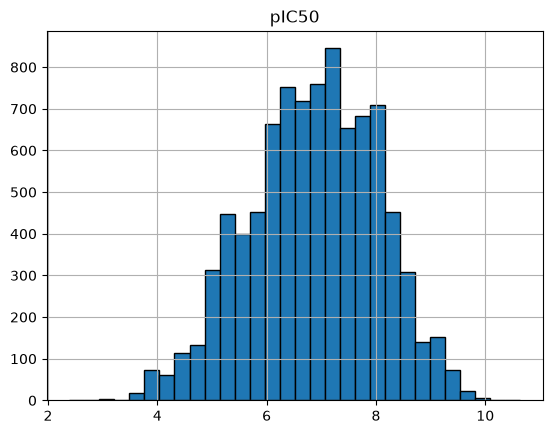

In [52]:
finaloutput_df.hist(column="pIC50", bins=30, edgecolor="black")

In [53]:
PandasTools.AddMoleculeColumnToFrame(finaloutput_df, smilesCol="smiles")


In [54]:
finaloutput_df = finaloutput_df.sort_values(by="pIC50", ascending=False).reset_index(drop=True)

In [55]:
finaloutput_df.drop("smiles", axis=1).head(10)

,molecule_chembl_id,IC50,IC50_units,pIC50,ROMol
0,CHEMBL5189340,0.023,nM,10.638272,<rdkit.Chem.rdchem.Mol object at 0x000001E5F58...
1,CHEMBL429743,0.030,nM,10.522879,<rdkit.Chem.rdchem.Mol object at 0x000001E5F57...
2,CHEMBL5557999,0.100,nM,10.000000,<rdkit.Chem.rdchem.Mol object at 0x000001E5F58...
3,CHEMBL5411585,0.110,nM,9.958607,<rdkit.Chem.rdchem.Mol object at 0x000001E5F58...
4,CHEMBL5186748,0.120,nM,9.920819,<rdkit.Chem.rdchem.Mol object at 0x000001E5F58...
5,CHEMBL3586072,0.140,nM,9.853872,<rdkit.Chem.rdchem.Mol object at 0x000001E5F57...
6,CHEMBL3093581,0.140,nM,9.853872,<rdkit.Chem.rdchem.Mol object at 0x000001E5F57...
7,CHEMBL3586071,0.150,nM,9.823909,<rdkit.Chem.rdchem.Mol object at 0x000001E5F57...
8,CHEMBL1289494,0.160,nM,9.795880,<rdkit.Chem.rdchem.Mol object at 0x000001E5F57...
9,CHEMBL2348996,0.190,nM,9.721246,<rdkit.Chem.rdchem.Mol object at 0x000001E5F57...


In [56]:
finaloutput_df = finaloutput_df.drop("ROMol", axis=1)
print(f'The shape of the final output data after dropping the ROMol column: {finaloutput_df.shape}')

The shape of the final output data after dropping the ROMol column: (8954, 5)


Saving the dataset

In [61]:
finaloutput_df.to_csv("data/VEGFR-2.csv", index=False)